# Clear MNIST ML pipeline: Keras + Prefect + Snowflake
## What runs where?
| Component | Role in this notebook |
|---|---|
| Keras in Colab | Loads MNIST, trains a digit classifier and predicts digits |
| Prefect | Coordinates tasks and records logs, timing and success/failure |
| Snowflake warehouse | Runs SQL for storing and inspecting experiment data |
| Snowflake database | Stores experiment, epoch, prediction and image-sample tables |
| Snowflake internal stage | Stores the uploaded `.keras` candidate model file |

**This notebook contains only MNIST.** Start with a fresh Google Colab session and run top to bottom. GPU is optional. Snowflake and Cloud keys are entered through hidden prompts. Live training requires access to the MNIST download source.

## Your Snowflake objects
| Object | Exact name | Where to inspect |
|---|---|---|
| Warehouse (compute) | ORCH_COMPARE_WH | SHOW WAREHOUSES |
| Database (data container) | ORCH_COMPARE_DB | SHOW DATABASES |
| Schema (table grouping) | PUBLIC | SHOW SCHEMAS IN DATABASE ORCH_COMPARE_DB |
| Experiment table | ML_RUNS | One row per experiment |
| Learning curves | ML_EPOCHS | One row per completed epoch |
| Prediction table | ML_PREDICTIONS | First 100 test predictions per experiment |
| Image samples | MNIST_SAMPLES | First 25 test images, labels and 784 raw pixels per experiment |
| Model files | MODEL_ARTIFACTS stage | LIST @ORCH_COMPARE_DB.PUBLIC.MODEL_ARTIFACTS |

A warehouse supplies compute; it does not contain the tables. Tables are addressed as DATABASE.SCHEMA.TABLE, for example `ORCH_COMPARE_DB.PUBLIC.ML_RUNS`.

**Expected row counts for one default run:** ML_RUNS=1, ML_EPOCHS=3, ML_PREDICTIONS=100, MNIST_SAMPLES=25. Historical experiments remain, so use RUN_ID to inspect one run. Actual accuracy is measured at runtime, not hardcoded.


## End-to-end flowchart

![MNIST flow](attachment:mnist-flow.png)

The seven boxes are seven Prefect task runs. Training and evaluation use Colab; Snowflake stores the outputs. A failed step stops downstream calls; configured tasks may retry.

## 1. Install
Colab normally already includes TensorFlow. Install the connector and Prefect; restart if the runtime requests it.

**Block summary:** Install the orchestration, database, training and visualization dependencies.

In [ ]:
# Install the packages needed by this notebook.
!pip install -q "prefect>=3,<4" snowflake-connector-python tensorflow pandas matplotlib

## 2. Choose optional connections
`USE_SNOWFLAKE = True` enables database writes. Set it to False for an local MNIST practice run without database credentials; Snowflake logging and upload will be skipped.

Enter a Prefect API key to use your existing Cloud workspace. Press Enter to keep run records locally in Colab. Cloud logs contain printed sample results and metrics. No deployment or schedule is required.

**Block summary:** Select Snowflake and configure optional Cloud logging before the first Prefect import.

In [ ]:
import os  # Configure Prefect before importing it.
from getpass import getpass  # Read secrets without printing them.

USE_SNOWFLAKE = True  # Keep True for the full comparison practical.
PREFECT_WORKSPACE_URL = "https://app.prefect.cloud/account/1db07649-353f-4e19-8021-644bee1b8296/workspace/d741b578-a867-4c10-b2b4-fb97fd4f7e80/home"
cloud_key = "" # Add your prefect key here
if cloud_key:  # Configure this session for your existing workspace.
    os.environ["PREFECT_API_URL"] = "https://api.prefect.cloud/api/accounts/1db07649-353f-4e19-8021-644bee1b8296/workspaces/d741b578-a867-4c10-b2b4-fb97fd4f7e80"
    os.environ["PREFECT_API_KEY"] = cloud_key  # Keep the key out of saved code.
    print("Dashboard:", PREFECT_WORKSPACE_URL)  # Open this link to inspect Runs.
else:  # Remove Cloud overrides when choosing local mode in a fresh session.
    os.environ.pop("PREFECT_API_KEY", None)
    os.environ.pop("PREFECT_API_URL", None)
    print("Local Prefect mode; a configured user profile can still affect the backend.")

Dashboard: https://app.prefect.cloud/account/1db07649-353f-4e19-8021-644bee1b8296/workspace/d741b578-a867-4c10-b2b4-fb97fd4f7e80/home


**Block summary:** Set a small, reproducible training configuration; models and arrays stay in memory between sequential tasks.

In [ ]:
import json  # Write a model manifest.
import uuid  # Assign a unique experiment identifier.
import time  # Measure training duration.
from pathlib import Path  # Manage local model artifacts.
import numpy as np  # Handle image arrays and predictions.
import pandas as pd  # Display SQL records as tables.
import matplotlib.pyplot as plt  # Draw learning curves and digit examples.
import tensorflow as tf  # Load MNIST and train the Keras model.
import snowflake.connector  # Connect Python to Snowflake.
from prefect import task, flow  # Record steps and workflow runs.
from prefect.cache_policies import NO_CACHE  # Avoid caching mutable model/array objects.
from IPython.display import display  # Show readable tables in Colab.

SEED = 42  # Fix the sampling and initialization seed.
EPOCHS = 3  # Keep the first run short; increase later for an experiment.
BATCH_SIZE = 128  # Number of images per training update.
N_TRAIN = 10000  # Use a random subset for a quick classroom demo.
N_VAL = 2000  # Keep a separate validation subset from the original training split.
MIN_VAL_ACCURACY = 0.85  # Classroom gate; not a guaranteed or production threshold.
ARTIFACT_DIR = Path("mnist_pipeline_artifacts")  # Local runtime folder for saved candidates.
ARTIFACT_DIR.mkdir(exist_ok=True)  # Make the folder if needed.
print("TensorFlow:", tf.__version__, "GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 GPU: []


## 3. Connect to Snowflake
Account settings are filled in. This notebook uses the existing ORCH_COMPARE objects and keeps historical ML records. Object comments are saved in Snowflake metadata, not just Python code. Your role needs privileges to create/alter these lesson objects. MFA/SSO may require your institution's connector settings. Warehouse compute incurs usage charges.

`USE_SNOWFLAKE=True` is needed for database tables and stage files. False runs the Keras lesson locally and skips Snowflake inspection cells.

**Block summary:** Create/select the warehouse, database and tables; save readable comments for every table and column; create a model-file stage.

In [ ]:
conn = None  # Keep local-only mode available.
if USE_SNOWFLAKE:  # Connect for the full Prefect + Snowflake practical.
    conn = snowflake.connector.connect(
        account="sr43506.ap-southeast-7.aws",  # Your account identifier.
        user="SUMUNTHRA",  # Your supplied user.
        role="ACCOUNTADMIN",  # Your supplied role.
        password=getpass("Snowflake password: "),  # Hidden password prompt.
    )
    with conn.cursor() as cur:  # Send setup SQL and close the cursor afterwards.
        cur.execute("CREATE WAREHOUSE IF NOT EXISTS ORCH_COMPARE_WH WAREHOUSE_SIZE='XSMALL' AUTO_SUSPEND=60 AUTO_RESUME=TRUE INITIALLY_SUSPENDED=TRUE")
        cur.execute("USE WAREHOUSE ORCH_COMPARE_WH")  # Select compute.
        cur.execute("CREATE DATABASE IF NOT EXISTS ORCH_COMPARE_DB")  # Create the database if missing.
        cur.execute("USE DATABASE ORCH_COMPARE_DB")  # Select the database.
        cur.execute("USE SCHEMA PUBLIC")  # Select the schema containing our tables.
        cur.execute("COMMENT ON WAREHOUSE ORCH_COMPARE_WH IS 'Compute for MNIST experiment SQL; Keras trains in Colab'")
        cur.execute("COMMENT ON DATABASE ORCH_COMPARE_DB IS 'Teaching database for Prefect orchestration and MNIST experiment results'")
        cur.execute("COMMENT ON SCHEMA ORCH_COMPARE_DB.PUBLIC IS 'MNIST run, epoch, prediction and image sample tables'")
        cur.execute("CREATE STAGE IF NOT EXISTS MODEL_ARTIFACTS")  # Durable Snowflake file storage.
        cur.execute("COMMENT ON STAGE MODEL_ARTIFACTS IS 'Keras candidate models uploaded per MNIST experiment; not an inference service'")
        # Create ml_runs without deleting prior experiment rows.
        cur.execute('CREATE TABLE IF NOT EXISTS ml_runs (\n    run_id VARCHAR,\n    seed INTEGER,\n    train_size INTEGER,\n    val_size INTEGER,\n    test_size INTEGER,\n    epochs INTEGER,\n    batch_size INTEGER,\n    val_accuracy FLOAT,\n    test_accuracy FLOAT,\n    test_loss FLOAT,\n    train_seconds FLOAT,\n    decision VARCHAR,\n    model_path VARCHAR,\n    created_at TIMESTAMP_LTZ DEFAULT CURRENT_TIMESTAMP(),\n    model_stage_uri VARCHAR\n)')
        # Create ml_epochs without deleting prior experiment rows.
        cur.execute('CREATE TABLE IF NOT EXISTS ml_epochs (\n    run_id VARCHAR,\n    epoch INTEGER,\n    loss FLOAT,\n    accuracy FLOAT,\n    val_loss FLOAT,\n    val_accuracy FLOAT\n)')
        # Create ml_predictions without deleting prior experiment rows.
        cur.execute('CREATE TABLE IF NOT EXISTS ml_predictions (\n    run_id VARCHAR,\n    sample_id INTEGER,\n    true_digit INTEGER,\n    predicted_digit INTEGER,\n    confidence FLOAT,\n    correct BOOLEAN\n)')
        # Create mnist_samples without deleting prior experiment rows.
        cur.execute('CREATE TABLE IF NOT EXISTS mnist_samples (\n    run_id VARCHAR,\n    sample_id INTEGER,\n    true_digit INTEGER,\n    pixels VARIANT,\n    split_name VARCHAR\n)')
        cur.execute("ALTER TABLE ml_runs ADD COLUMN IF NOT EXISTS model_stage_uri VARCHAR")  # Extend an earlier version safely.
        cur.execute("COMMENT ON TABLE ml_runs IS 'MNIST experiment settings, measured metrics and model file locations; one row per run'")  # Save table purpose in Snowflake.
        cur.execute("COMMENT ON COLUMN ml_runs.run_id IS 'Unique experiment ID joining all ML tables and candidate files'")  # Document run_id.
        cur.execute("COMMENT ON COLUMN ml_runs.seed IS 'Random seed used for sampling and model initialization'")  # Document seed.
        cur.execute("COMMENT ON COLUMN ml_runs.train_size IS 'Number of images used to update model weights'")  # Document train_size.
        cur.execute("COMMENT ON COLUMN ml_runs.val_size IS 'Number of separate validation images'")  # Document val_size.
        cur.execute("COMMENT ON COLUMN ml_runs.test_size IS 'Number of held-out images in final test evaluation'")  # Document test_size.
        cur.execute("COMMENT ON COLUMN ml_runs.epochs IS 'Completed training epochs'")  # Document epochs.
        cur.execute("COMMENT ON COLUMN ml_runs.batch_size IS 'Images per training minibatch'")  # Document batch_size.
        cur.execute("COMMENT ON COLUMN ml_runs.val_accuracy IS 'Validation accuracy as fraction from 0 to 1'")  # Document val_accuracy.
        cur.execute("COMMENT ON COLUMN ml_runs.test_accuracy IS 'Accuracy on the full held-out test set as fraction'")  # Document test_accuracy.
        cur.execute("COMMENT ON COLUMN ml_runs.test_loss IS 'Sparse categorical cross-entropy on held-out test images'")  # Document test_loss.
        cur.execute("COMMENT ON COLUMN ml_runs.train_seconds IS 'Time spent in model.fit in Colab'")  # Document train_seconds.
        cur.execute("COMMENT ON COLUMN ml_runs.decision IS 'PASS_VALIDATION or REVIEW using validation threshold only'")  # Document decision.
        cur.execute("COMMENT ON COLUMN ml_runs.model_path IS 'Local Colab candidate path; not permanent storage'")  # Document model_path.
        cur.execute("COMMENT ON COLUMN ml_runs.created_at IS 'Snowflake timestamp when the run record is written'")  # Document created_at.
        cur.execute("COMMENT ON COLUMN ml_runs.model_stage_uri IS 'Snowflake internal stage location of the saved candidate'")  # Document model_stage_uri.
        cur.execute("COMMENT ON TABLE ml_epochs IS 'Per-epoch Keras training and validation curves for each MNIST experiment'")  # Save table purpose in Snowflake.
        cur.execute("COMMENT ON COLUMN ml_epochs.run_id IS 'Experiment ID linked to ML_RUNS'")  # Document run_id.
        cur.execute("COMMENT ON COLUMN ml_epochs.epoch IS 'Training epoch starting from 1'")  # Document epoch.
        cur.execute("COMMENT ON COLUMN ml_epochs.loss IS 'Training sparse categorical cross-entropy'")  # Document loss.
        cur.execute("COMMENT ON COLUMN ml_epochs.accuracy IS 'Training accuracy fraction'")  # Document accuracy.
        cur.execute("COMMENT ON COLUMN ml_epochs.val_loss IS 'Validation sparse categorical cross-entropy'")  # Document val_loss.
        cur.execute("COMMENT ON COLUMN ml_epochs.val_accuracy IS 'Validation accuracy fraction'")  # Document val_accuracy.
        cur.execute("COMMENT ON TABLE ml_predictions IS 'First 100 held-out MNIST test predictions; sample accuracy is not full test accuracy'")  # Save table purpose in Snowflake.
        cur.execute("COMMENT ON COLUMN ml_predictions.run_id IS 'Experiment ID linked to ML_RUNS'")  # Document run_id.
        cur.execute("COMMENT ON COLUMN ml_predictions.sample_id IS 'Zero-based index in official MNIST test split; only first 100 recorded'")  # Document sample_id.
        cur.execute("COMMENT ON COLUMN ml_predictions.true_digit IS 'Ground truth digit label from 0 to 9'")  # Document true_digit.
        cur.execute("COMMENT ON COLUMN ml_predictions.predicted_digit IS 'Digit with highest softmax output'")  # Document predicted_digit.
        cur.execute("COMMENT ON COLUMN ml_predictions.confidence IS 'Maximum softmax score; not calibrated certainty'")  # Document confidence.
        cur.execute("COMMENT ON COLUMN ml_predictions.correct IS 'True when predicted_digit equals true_digit'")  # Document correct.
        cur.execute("COMMENT ON TABLE mnist_samples IS 'First 25 held-out MNIST digit images as pixel arrays; demonstration samples, not full training data'")  # Save table purpose in Snowflake.
        cur.execute("COMMENT ON COLUMN mnist_samples.run_id IS 'Experiment ID linked to ML_RUNS'")  # Document run_id.
        cur.execute("COMMENT ON COLUMN mnist_samples.sample_id IS 'Zero-based official test-split index; first 25 samples only'")  # Document sample_id.
        cur.execute("COMMENT ON COLUMN mnist_samples.true_digit IS 'Ground truth digit from 0 to 9'")  # Document true_digit.
        cur.execute("COMMENT ON COLUMN mnist_samples.pixels IS 'Array of 784 original-scale pixel integers 0 to 255 in row-major order'")  # Document pixels.
        cur.execute("COMMENT ON COLUMN mnist_samples.split_name IS 'TEST identifies these as held-out examples'")  # Document split_name.
    print("Ready: ORCH_COMPARE_WH → ORCH_COMPARE_DB.PUBLIC; 4 ML tables and MODEL_ARTIFACTS stage")


Snowflake password: ··········
Ready: ORCH_COMPARE_WH → ORCH_COMPARE_DB.PUBLIC; 4 ML tables and MODEL_ARTIFACTS stage


**Block summary:** Provide small database helpers used by the ML pipeline.

In [ ]:
def execute_sql(sql, params=None):  # Send one statement with optional bound values.
    with conn.cursor() as cur:
        cur.execute(sql, params or ())  # Keep data values separate from SQL text.

def sql_table(sql, params=None):  # Read and display a result table.
    with conn.cursor() as cur:
        cur.execute(sql, params or ())
        frame = pd.DataFrame(cur.fetchall(), columns=[c[0] for c in cur.description])
    display(frame)  # Render rows and columns in the notebook.
    return frame  # Return the result for further analysis.

## 4. Inspect Snowflake BEFORE training
Run these cells to confirm where objects live. Tables may be empty before the first successful pipeline run. SHOW lists metadata, DESCRIBE shows structure, and SELECT reads actual rows.

`--` comments explain a SQL script but are not saved as object metadata. `COMMENT ON ...` above stores comments that remain visible through DESCRIBE, SHOW and INFORMATION_SCHEMA.

**Block summary:** Locate compute and storage objects; read the comments that explain each stored column.

In [ ]:
if USE_SNOWFLAKE:
    sql_table("SELECT CURRENT_USER() AS active_user, CURRENT_ROLE() AS active_role, CURRENT_WAREHOUSE() AS warehouse, CURRENT_DATABASE() AS database_name, CURRENT_SCHEMA() AS schema_name")  # Show active context.
    sql_table("SHOW WAREHOUSES LIKE 'ORCH_COMPARE_WH'")  # See warehouse state, size and comment.
    sql_table("SHOW DATABASES LIKE 'ORCH_COMPARE_DB'")  # Find database and comment.
    sql_table("SHOW SCHEMAS IN DATABASE ORCH_COMPARE_DB")  # See schema names.
    sql_table("SHOW TABLES IN SCHEMA ORCH_COMPARE_DB.PUBLIC")  # Find the four tables (and any older lesson tables).
    sql_table("DESCRIBE TABLE ORCH_COMPARE_DB.PUBLIC.ML_RUNS")  # See types and column comments.
    sql_table("""
        -- Show saved column documentation for the four ML tables.
        SELECT TABLE_NAME, COLUMN_NAME, DATA_TYPE, COMMENT
        FROM ORCH_COMPARE_DB.INFORMATION_SCHEMA.COLUMNS
        WHERE TABLE_SCHEMA = 'PUBLIC'
          AND TABLE_NAME IN ('ML_RUNS','ML_EPOCHS','ML_PREDICTIONS','MNIST_SAMPLES')
        ORDER BY TABLE_NAME, ORDINAL_POSITION
    """)

,ACTIVE_USER,ACTIVE_ROLE,WAREHOUSE,DATABASE_NAME,SCHEMA_NAME
0,SUMUNTHRA,ACCOUNTADMIN,ORCH_COMPARE_WH,ORCH_COMPARE_DB,PUBLIC


,name,state,type,size,min_cluster_count,max_cluster_count,started_clusters,running,queued,is_default,...,suspended,uuid,scaling_policy,owner_role_type,resource_constraint,generation,query_throughput_multiplier,max_query_performance_level,disabled_reasons,tables
0,ORCH_COMPARE_WH,SUSPENDED,STANDARD,X-Small,1,1,0,0,0,N,...,1,10658120485,STANDARD,ROLE,STANDARD_GEN_2,2,None,None,None,None


,created_on,name,is_default,is_current,origin,owner,comment,options,retention_time,kind,owner_role_type,object_visibility,data_quality_monitoring_settings,resharing_settings
0,2026-10-07 23:49:36.239000-07:00,ORCH_COMPARE_DB,N,Y,,ACCOUNTADMIN,Teaching database for Prefect orchestration an...,,1,STANDARD,ROLE,None,None,None


,created_on,name,is_default,is_current,database_name,owner,comment,options,retention_time,owner_role_type,classification_profile_database,classification_profile_schema,classification_profile,object_visibility,is_nested
0,2026-10-08 23:52:43.028000-07:00,INFORMATION_SCHEMA,N,N,ORCH_COMPARE_DB,,Views describing the contents of schemas in th...,,1,,None,None,None,None,false
1,2026-10-07 23:49:36.259000-07:00,PUBLIC,N,Y,ORCH_COMPARE_DB,ACCOUNTADMIN,"MNIST run, epoch, prediction and image sample ...",,1,ROLE,None,None,None,None,false


,created_on,name,database_name,schema_name,kind,comment,cluster_by,rows,bytes,owner,...,enable_schema_evolution,owner_role_type,is_event,is_hybrid,is_iceberg,is_dynamic,is_immutable,is_interactive,row_timestamp,error_logging
0,2026-10-07 23:56:27.272000-07:00,CLEAN_ORDERS,ORCH_COMPARE_DB,PUBLIC,TABLE,,,3,1024,ACCOUNTADMIN,...,N,ROLE,N,N,N,N,N,N,OFF,OFF
1,2026-10-07 23:49:37.691000-07:00,ML_EPOCHS,ORCH_COMPARE_DB,PUBLIC,TABLE,Per-epoch Keras training and validation curves...,,6,1536,ACCOUNTADMIN,...,N,ROLE,N,N,N,N,N,N,OFF,OFF
2,2026-10-07 23:49:38.117000-07:00,ML_PREDICTIONS,ORCH_COMPARE_DB,PUBLIC,TABLE,First 100 held-out MNIST test predictions; sam...,,200,2560,ACCOUNTADMIN,...,N,ROLE,N,N,N,N,N,N,OFF,OFF
3,2026-10-07 23:49:37.231000-07:00,ML_RUNS,ORCH_COMPARE_DB,PUBLIC,TABLE,"MNIST experiment settings, measured metrics an...",,2,2048,ACCOUNTADMIN,...,N,ROLE,N,N,N,N,N,N,OFF,OFF
4,2026-10-08 23:07:09.920000-07:00,MNIST_SAMPLES,ORCH_COMPARE_DB,PUBLIC,TABLE,First 25 held-out MNIST digit images as pixel ...,,25,10240,ACCOUNTADMIN,...,N,ROLE,N,N,N,N,N,N,OFF,OFF
5,2026-10-07 23:56:28.038000-07:00,ORDER_SUMMARY,ORCH_COMPARE_DB,PUBLIC,TABLE,,,1,1024,ACCOUNTADMIN,...,N,ROLE,N,N,N,N,N,N,OFF,OFF
6,2026-10-07 23:56:26.103000-07:00,RAW_ORDERS,ORCH_COMPARE_DB,PUBLIC,TABLE,,,3,1024,ACCOUNTADMIN,...,N,ROLE,N,N,N,N,N,N,OFF,OFF


,name,type,kind,null?,default,primary key,unique key,check,expression,comment,policy name,privacy domain,write default
0,RUN_ID,VARCHAR(16777216),COLUMN,Y,None,N,N,None,None,Unique experiment ID joining all ML tables and...,None,None,None
1,SEED,"NUMBER(38,0)",COLUMN,Y,None,N,N,None,None,Random seed used for sampling and model initia...,None,None,None
2,TRAIN_SIZE,"NUMBER(38,0)",COLUMN,Y,None,N,N,None,None,Number of images used to update model weights,None,None,None
3,VAL_SIZE,"NUMBER(38,0)",COLUMN,Y,None,N,N,None,None,Number of separate validation images,None,None,None
4,TEST_SIZE,"NUMBER(38,0)",COLUMN,Y,None,N,N,None,None,Number of held-out images in final test evalua...,None,None,None
5,EPOCHS,"NUMBER(38,0)",COLUMN,Y,None,N,N,None,None,Completed training epochs,None,None,None
6,BATCH_SIZE,"NUMBER(38,0)",COLUMN,Y,None,N,N,None,None,Images per training minibatch,None,None,None
7,VAL_ACCURACY,FLOAT,COLUMN,Y,None,N,N,None,None,Validation accuracy as fraction from 0 to 1,None,None,None
8,TEST_ACCURACY,FLOAT,COLUMN,Y,None,N,N,None,None,Accuracy on the full held-out test set as frac...,None,None,None
9,TEST_LOSS,FLOAT,COLUMN,Y,None,N,N,None,None,Sparse categorical cross-entropy on held-out t...,None,None,None


,TABLE_NAME,COLUMN_NAME,DATA_TYPE,COMMENT
0,ML_EPOCHS,RUN_ID,TEXT,Experiment ID linked to ML_RUNS
1,ML_EPOCHS,EPOCH,NUMBER,Training epoch starting from 1
2,ML_EPOCHS,LOSS,FLOAT,Training sparse categorical cross-entropy
3,ML_EPOCHS,ACCURACY,FLOAT,Training accuracy fraction
4,ML_EPOCHS,VAL_LOSS,FLOAT,Validation sparse categorical cross-entropy
5,ML_EPOCHS,VAL_ACCURACY,FLOAT,Validation accuracy fraction
6,ML_PREDICTIONS,RUN_ID,TEXT,Experiment ID linked to ML_RUNS
7,ML_PREDICTIONS,SAMPLE_ID,NUMBER,Zero-based index in official MNIST test split;...
8,ML_PREDICTIONS,TRUE_DIGIT,NUMBER,Ground truth digit label from 0 to 9
9,ML_PREDICTIONS,PREDICTED_DIGIT,NUMBER,Digit with highest softmax output


## 5. ML stage A: load and validate MNIST
MNIST provides 60,000 training and 10,000 test grayscale digit images, each 28×28, with integer labels 0–9. We reserve test images for final evaluation.

Tasks disable caching and result persistence because this small sequential demo passes large arrays and a live model in memory. A distributed production pipeline would pass dataset/model locations and versioned artifacts instead.

**Block summary:** Validate image/label ranges and create disjoint train and validation subsets; normalize with the fixed 255 scale.

In [ ]:
@task(retries=2, retry_delay_seconds=3, cache_policy=NO_CACHE, persist_result=False)
def load_mnist():  # A download may be retried after a temporary network failure.
    (x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
    print("Loaded MNIST:", x_train.shape, x_test.shape)
    return x_train, y_train, x_test, y_test

@task(cache_policy=NO_CACHE, persist_result=False)
def prepare_mnist(raw):  # Check input, then split and scale without using test labels.
    x_source, y_source, x_test, y_test = raw
    for x, y in [(x_source, y_source), (x_test, y_test)]:
        if x.shape[1:] != (28, 28) or len(x) != len(y):
            raise ValueError("Unexpected image shape or label count")
        if x.min() < 0 or x.max() > 255 or y.min() < 0 or y.max() > 9:
            raise ValueError("Pixels or labels outside expected ranges")
    if N_TRAIN < 1 or N_VAL < 1 or N_TRAIN + N_VAL > len(x_source):
        raise ValueError("Choose positive, disjoint training and validation sizes")
    rng = np.random.default_rng(SEED)  # Seed the random row selection.
    indices = rng.permutation(len(x_source))  # Shuffle the original training split only.
    train_ids = indices[:N_TRAIN]  # Select training images.
    val_ids = indices[N_TRAIN:N_TRAIN + N_VAL]  # Select separate validation images.
    data = {
        "x_train": x_source[train_ids].astype("float32") / 255.0,
        "y_train": y_source[train_ids],
        "x_val": x_source[val_ids].astype("float32") / 255.0,
        "y_val": y_source[val_ids],
        "x_test": x_test.astype("float32") / 255.0,
        "y_test": y_test,
    }
    if len(np.unique(data["y_train"])) != 10 or len(np.unique(data["y_val"])) != 10:
        raise ValueError("Selected train/validation subsets must contain all ten digits")
    print("Prepared train/validation/test:", N_TRAIN, N_VAL, len(y_test))
    return data

## 6. ML stage B: train a Keras classifier
Flatten converts 28×28 pixels into 784 features. A hidden layer learns 64 nonlinear features. Ten softmax outputs represent the digit probabilities. Sparse cross-entropy accepts integer labels, so one-hot encoding is unnecessary.

Training uses Adam. Validation measures generalization while training; it does not update weights. Training is not automatically retried because repeating it can be expensive.

**Block summary:** Train a small dense classifier and return its per-epoch learning curves and measured training time.

In [ ]:
@task(cache_policy=NO_CACHE, persist_result=False)
def train_classifier(data):  # Learn model weights from the training subset.
    tf.keras.backend.clear_session()  # Release the previous model's Keras state.
    tf.keras.utils.set_random_seed(SEED)  # Seed initialization and data shuffling.
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),  # Accept normalized grayscale images.
        tf.keras.layers.Flatten(),  # Turn each image into 784 features.
        tf.keras.layers.Dense(64, activation="relu"),  # Learn nonlinear features.
        tf.keras.layers.Dense(10, activation="softmax"),  # Output ten digit probabilities.
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    start = time.perf_counter()  # Measure fit duration only.
    history = model.fit(
        data["x_train"], data["y_train"],  # Learn from training rows only.
        validation_data=(data["x_val"], data["y_val"]),  # Observe a separate validation subset.
        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2,  # Print epoch-level results.
    )
    seconds = time.perf_counter() - start  # Stop the training timer.
    print("Training seconds:", round(seconds, 2))
    return model, history.history, seconds  # Pass the live model and curves to later tasks.

## 7. ML stage C: evaluate and decide
We compute validation accuracy first and apply the fixed classroom threshold. We then evaluate the untouched test set for final reporting; its accuracy does not determine the gate.

A candidate below the threshold receives `REVIEW`, and one above it receives `PASS_VALIDATION`. Both are recorded. The threshold is a lesson rule, not proof of production readiness. Repeated tuning against the same test set would invalidate its role as an unbiased final assessment.

**Block summary:** Apply a validation-only gate, evaluate the held-out test set and generate predictions without promising an accuracy.

In [ ]:
@task(cache_policy=NO_CACHE, persist_result=False)
def evaluate_classifier(model, data):  # Compare predictions with labels after training.
    val_metrics = model.evaluate(data["x_val"], data["y_val"], verbose=0, return_dict=True)
    decision = "PASS_VALIDATION" if val_metrics["accuracy"] >= MIN_VAL_ACCURACY else "REVIEW"
    test_metrics = model.evaluate(data["x_test"], data["y_test"], verbose=0, return_dict=True)
    probabilities = model.predict(data["x_test"], batch_size=BATCH_SIZE, verbose=0)
    predictions = np.argmax(probabilities, axis=1)  # Choose the most probable digit.
    confidence = np.max(probabilities, axis=1)  # Highest probability; not calibrated certainty.
    metrics = {"val_accuracy": float(val_metrics["accuracy"]),
               "test_accuracy": float(test_metrics["accuracy"]),
               "test_loss": float(test_metrics["loss"]), "decision": decision}
    print("ML evaluation:", metrics)
    return metrics, predictions, confidence

## 8. Save the model and write results to Snowflake
The local `.keras` file and JSON manifest are saved first. PUT uploads the model to an internal stage under its RUN_ID. Snowflake therefore holds both tabular results and the candidate model file.

The record-writing task stores one experiment, its epochs, 100 test predictions and 25 actual test images. Pixels are reconstructed from the fixed normalization and stored as a VARIANT array. These 25 examples help you inspect rows and image content; the full MNIST data remains in Colab.

Database writes use a transaction and reset only the current RUN_ID on retries. Historical runs remain. A partially failed flow may leave an uploaded candidate without a completed run record; no predictor is deployed automatically.
PUT runs through the Python connector in Colab; Snowflake web worksheets cannot run local-file PUT commands. Use LIST in a worksheet to inspect the uploaded model.


**Block summary:** Save candidate and manifest; upload the model to Snowflake; transactionally record metrics, epochs, predictions and image sample rows.

In [ ]:
@task(cache_policy=NO_CACHE, persist_result=False)
def save_candidate(model, run_id, metrics, seconds):  # Save a candidate irrespective of gate status.
    path = ARTIFACT_DIR / f"{run_id}.keras"  # One file per run.
    model.save(path)  # Serialize architecture and trained weights.
    manifest = {"run_id": run_id, "dataset": "MNIST", "seed": SEED,
                "train_size": N_TRAIN, "val_size": N_VAL, "epochs": EPOCHS,
                "batch_size": BATCH_SIZE, "threshold": MIN_VAL_ACCURACY,
                "train_seconds": seconds, "tensorflow": tf.__version__, **metrics}
    path.with_suffix(".json").write_text(json.dumps(manifest, indent=2))  # Save metadata beside the model.
    print("Saved candidate:", path)
    return str(path)

@task(retries=2, retry_delay_seconds=3, cache_policy=NO_CACHE, persist_result=False)
def upload_model(model_path, run_id):  # Upload the trained candidate, not a serving deployment.
    if not USE_SNOWFLAKE:
        return None  # Leave the candidate local in offline mode.
    file_uri = Path(model_path).resolve().as_uri()  # Form a local file URI for PUT.
    stage_uri = f"@ORCH_COMPARE_DB.PUBLIC.MODEL_ARTIFACTS/{run_id}/{Path(model_path).name}"
    with conn.cursor() as cur:
        cur.execute(f"PUT '{file_uri}' @ORCH_COMPARE_DB.PUBLIC.MODEL_ARTIFACTS/{run_id}/ AUTO_COMPRESS=FALSE OVERWRITE=TRUE")  # Retry overwrites this run's same file.
        put_rows = cur.fetchall()  # Read PUT status output.
    if not put_rows or any(str(row[6]).upper() not in {"UPLOADED", "SKIPPED"} for row in put_rows):
        raise RuntimeError(f"Model upload did not complete: {put_rows}")
    print("Snowflake candidate:", stage_uri)
    return stage_uri  # Persist the stage locator in ML_RUNS.

@task(retries=2, retry_delay_seconds=3, cache_policy=NO_CACHE, persist_result=False)
def record_experiment(run_id, history, seconds, metrics, predictions, confidence, labels, model_path, images, stage_uri):
    if not USE_SNOWFLAKE:  # Allow the training lesson without a database account.
        print("Snowflake logging skipped; local candidate and manifest are saved.")
        return
    with conn.cursor() as cur:
        cur.execute("BEGIN")  # Group the experiment record writes into one transaction.
        try:
            for table in ["mnist_samples", "ml_predictions", "ml_epochs", "ml_runs"]:
                cur.execute(f"DELETE FROM {table} WHERE run_id = %s", (run_id,))  # Reset only this run.
            cur.execute("""
                INSERT INTO ml_runs
                (run_id, seed, train_size, val_size, test_size, epochs, batch_size,
                 val_accuracy, test_accuracy, test_loss, train_seconds, decision, model_path, model_stage_uri)
                VALUES (%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s)
            """, (run_id, SEED, N_TRAIN, N_VAL, len(labels), len(history["loss"]), BATCH_SIZE,
                  metrics["val_accuracy"], metrics["test_accuracy"], metrics["test_loss"],
                  seconds, metrics["decision"], model_path, stage_uri))
            epoch_rows = [(run_id, i + 1, float(history["loss"][i]), float(history["accuracy"][i]),
                           float(history["val_loss"][i]), float(history["val_accuracy"][i]))
                          for i in range(len(history["loss"]))]  # One record per completed epoch.
            cur.executemany("INSERT INTO ml_epochs VALUES (%s,%s,%s,%s,%s,%s)", epoch_rows)
            prediction_rows = [(run_id, i, int(labels[i]), int(predictions[i]), float(confidence[i]),
                                bool(labels[i] == predictions[i])) for i in range(min(100, len(labels)))]
            cur.executemany("INSERT INTO ml_predictions VALUES (%s,%s,%s,%s,%s,%s)", prediction_rows)
            # Save 25 real MNIST images as visible rows with a 784-element pixel array.
            for i in range(min(25, len(labels))):
                pixels = np.rint(images[i] * 255).astype("uint8").reshape(-1).tolist()  # Reverse fixed pixel scaling.
                cur.execute("""
                    -- PARSE_JSON stores the pixel list as a Snowflake VARIANT array.
                    INSERT INTO mnist_samples (run_id, sample_id, true_digit, pixels, split_name)
                    SELECT %s, %s, %s, PARSE_JSON(%s), %s
                """, (run_id, i, int(labels[i]), json.dumps(pixels), "TEST"))
            cur.execute("COMMIT")  # Make this experiment's records visible together.
        except Exception:
            cur.execute("ROLLBACK")  # Undo partial records before Prefect retries.
            raise
    print("Experiment recorded in Snowflake:", run_id)

## 9. Run the seven-task Prefect ML flow
RUN_ID is printed after the flow. Copy it when you want to filter SQL to this specific experiment. The validation decision is measured before final test reporting; it is not a production deployment approval.

**Block summary:** Run load → prepare → train → evaluate → save → upload → record; return metrics and images for inspection.

In [ ]:
@flow(name="mnist-keras-prefect-snowflake", log_prints=True)
def ml_pipeline():
    run_id = uuid.uuid4().hex  # Identify this experiment independently of previous runs.
    raw = load_mnist()  # Read the official dataset splits.
    data = prepare_mnist(raw)  # Validate, split and normalize.
    model, history, seconds = train_classifier(data)  # Learn weights.
    metrics, predictions, confidence = evaluate_classifier(model, data)  # Gate and evaluate.
    path = save_candidate(model, run_id, metrics, seconds)  # Save the trained candidate.
    stage_uri = upload_model(path, run_id)  # Upload the candidate file after saving.
    record_experiment(run_id, history, seconds, metrics, predictions, confidence, data["y_test"], path, data["x_test"], stage_uri)
    return {"run_id": run_id, "history": history, "metrics": metrics,
            "predictions": predictions, "confidence": confidence,
            "model_stage_uri": stage_uri, "images": data["x_test"], "labels": data["y_test"], "model_path": path}

ml_result = ml_pipeline()  # Start the full seven-task ML flow.
print("Run:", ml_result["run_id"], "Metrics:", ml_result["metrics"])

INFO:prefect.flow_runs:Beginning flow run 'delectable-swine' for flow 'mnist-keras-prefect-snowflake'
INFO:prefect.flow_runs:View at https://app.prefect.cloud/account/1db07649-353f-4e19-8021-644bee1b8296/workspace/d741b578-a867-4c10-b2b4-fb97fd4f7e80/runs/flow-run/06ac890d-cab9-71a9-8000-a968d28c4703
INFO:prefect.task_runs:Loaded MNIST: (60000, 28, 28) (10000, 28, 28)
INFO:prefect.task_runs:Finished in state Completed()
INFO:prefect.task_runs:Prepared train/validation/test: 10000 2000 10000
INFO:prefect.task_runs:Finished in state Completed()


Epoch 1/3
79/79 - 2s - 19ms/step - accuracy: 0.7385 - loss: 0.9835 - val_accuracy: 0.8830 - val_loss: 0.4772
Epoch 2/3
79/79 - 1s - 6ms/step - accuracy: 0.8927 - loss: 0.3979 - val_accuracy: 0.9065 - val_loss: 0.3623
Epoch 3/3
79/79 - 1s - 6ms/step - accuracy: 0.9135 - loss: 0.3193 - val_accuracy: 0.9165 - val_loss: 0.3178


INFO:prefect.task_runs:Training seconds: 2.67
INFO:prefect.task_runs:Finished in state Completed()
INFO:prefect.task_runs:ML evaluation: {'val_accuracy': 0.9164999723434448, 'test_accuracy': 0.9133999943733215, 'test_loss': 0.3052586317062378, 'decision': 'PASS_VALIDATION'}
INFO:prefect.task_runs:Finished in state Completed()
INFO:prefect.task_runs:Saved candidate: mnist_pipeline_artifacts/34ef75e5689c499fba1f921525043049.keras
INFO:prefect.task_runs:Finished in state Completed()
INFO:prefect.task_runs:Snowflake candidate: @ORCH_COMPARE_DB.PUBLIC.MODEL_ARTIFACTS/34ef75e5689c499fba1f921525043049/34ef75e5689c499fba1f921525043049.keras
INFO:prefect.task_runs:Finished in state Completed()
INFO:prefect.task_runs:Experiment recorded in Snowflake: 34ef75e5689c499fba1f921525043049
INFO:prefect.task_runs:Finished in state Completed()
INFO:prefect.flow_runs:Finished in state Completed()


Run: 34ef75e5689c499fba1f921525043049 Metrics: {'val_accuracy': 0.9164999723434448, 'test_accuracy': 0.9133999943733215, 'test_loss': 0.3052586317062378, 'decision': 'PASS_VALIDATION'}


## 10. Visual outputs
Training accuracy shows fit to examples used for learning. Validation accuracy shows performance on a separate subset. A widening gap can indicate overfitting. Test accuracy is measured after training, not drawn as a training curve.

**Block summary:** Plot learning curves, actual image predictions and a confusion matrix over all test images.

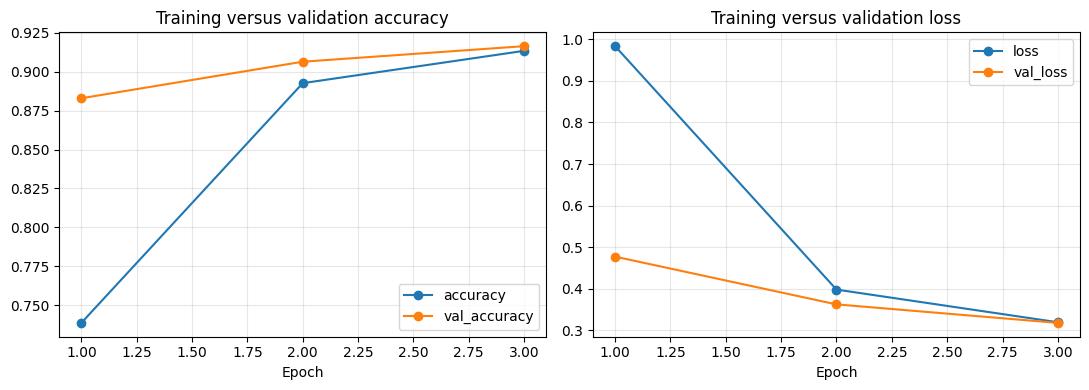

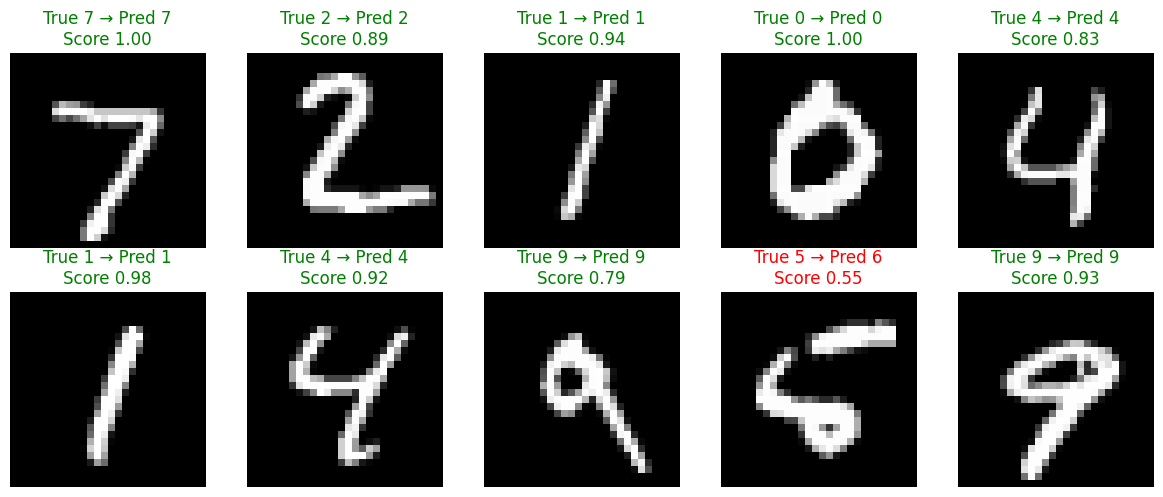

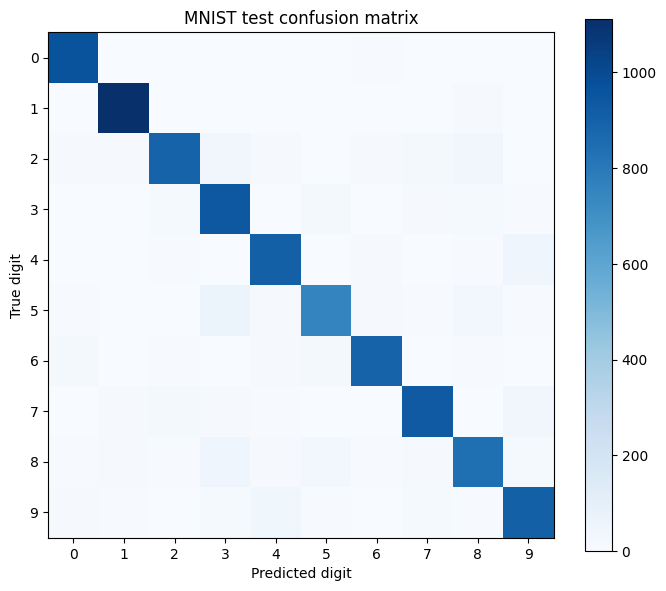

In [ ]:
history = ml_result["history"]  # Read the recorded epoch curves.
epochs = np.arange(1, len(history["loss"]) + 1)  # Display epochs starting at one.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label in ["accuracy", "val_accuracy"]:
    axes[0].plot(epochs, history[label], marker="o", label=label)
for label in ["loss", "val_loss"]:
    axes[1].plot(epochs, history[label], marker="o", label=label)
for ax, title in zip(axes, ["Training versus validation accuracy", "Training versus validation loss"]):
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))  # Inspect ten actual test images.
for i, ax in enumerate(axes.ravel()):
    ax.imshow(ml_result["images"][i], cmap="gray")
    true, pred = int(ml_result["labels"][i]), int(ml_result["predictions"][i])
    ax.set_title(f"True {true} → Pred {pred}\nScore {ml_result['confidence'][i]:.2f}",
                 color="green" if true == pred else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

cm = np.zeros((10, 10), dtype=int)  # Rows=true digits; columns=predictions.
np.add.at(cm, (ml_result["labels"], ml_result["predictions"]), 1)  # Count every test example.
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel("Predicted digit"); plt.ylabel("True digit"); plt.title("MNIST test confusion matrix")
plt.tight_layout(); plt.show()

## 11. Read actual stored rows AFTER the flow
Use the exact RUN_ID so historical runs do not confuse counts. The sample prediction accuracy uses only 100 stored rows and can differ from full test accuracy.

Expected default result: one ML_RUNS record; three ML_EPOCHS records; 100 ML_PREDICTIONS records; 25 MNIST_SAMPLES records; one staged candidate file.

**Block summary:** Query real rows and exact per-run counts; inspect stored image pixels, mistakes and the model file.

In [ ]:
if USE_SNOWFLAKE:
    run_id = ml_result["run_id"]  # Filter every query to the completed experiment.
    sql_table("SELECT * FROM ORCH_COMPARE_DB.PUBLIC.ML_RUNS WHERE run_id = %s", (run_id,))
    sql_table("SELECT * FROM ORCH_COMPARE_DB.PUBLIC.ML_EPOCHS WHERE run_id = %s ORDER BY epoch", (run_id,))
    sql_table("SELECT * FROM ORCH_COMPARE_DB.PUBLIC.ML_PREDICTIONS WHERE run_id = %s ORDER BY sample_id LIMIT 20", (run_id,))
    sql_table("SELECT sample_id, true_digit, split_name, ARRAY_SIZE(pixels) AS pixel_count, pixels FROM ORCH_COMPARE_DB.PUBLIC.MNIST_SAMPLES WHERE run_id = %s ORDER BY sample_id LIMIT 5", (run_id,))
    for table in ["ML_RUNS", "ML_EPOCHS", "ML_PREDICTIONS", "MNIST_SAMPLES"]:
        sql_table(f"SELECT '{table}' AS table_name, COUNT(*) AS rows_for_run FROM ORCH_COMPARE_DB.PUBLIC.{table} WHERE run_id = %s", (run_id,))
    sql_table(f"LIST @ORCH_COMPARE_DB.PUBLIC.MODEL_ARTIFACTS/{run_id}/")  # See the candidate filename and size.
    sql_table("SELECT sample_id, true_digit, predicted_digit, confidence FROM ML_PREDICTIONS WHERE run_id = %s AND correct = FALSE ORDER BY sample_id", (run_id,))  # Inspect mistakes among the first 100 predictions.

,RUN_ID,SEED,TRAIN_SIZE,VAL_SIZE,TEST_SIZE,EPOCHS,BATCH_SIZE,VAL_ACCURACY,TEST_ACCURACY,TEST_LOSS,TRAIN_SECONDS,DECISION,MODEL_PATH,CREATED_AT,MODEL_STAGE_URI
0,34ef75e5689c499fba1f921525043049,42,10000,2000,10000,3,128,0.9165,0.9134,0.305259,2.670313,PASS_VALIDATION,mnist_pipeline_artifacts/34ef75e5689c499fba1f9...,2026-10-08 23:59:51.841000-07:00,@ORCH_COMPARE_DB.PUBLIC.MODEL_ARTIFACTS/34ef75...


,RUN_ID,EPOCH,LOSS,ACCURACY,VAL_LOSS,VAL_ACCURACY
0,34ef75e5689c499fba1f921525043049,1,0.983460,0.7385,0.477150,0.8830
1,34ef75e5689c499fba1f921525043049,2,0.397889,0.8927,0.362313,0.9065
2,34ef75e5689c499fba1f921525043049,3,0.319304,0.9135,0.317782,0.9165


,RUN_ID,SAMPLE_ID,TRUE_DIGIT,PREDICTED_DIGIT,CONFIDENCE,CORRECT
0,34ef75e5689c499fba1f921525043049,0,7,7,0.996904,True
1,34ef75e5689c499fba1f921525043049,1,2,2,0.894327,True
2,34ef75e5689c499fba1f921525043049,2,1,1,0.944831,True
3,34ef75e5689c499fba1f921525043049,3,0,0,0.996135,True
4,34ef75e5689c499fba1f921525043049,4,4,4,0.829005,True
5,34ef75e5689c499fba1f921525043049,5,1,1,0.977638,True
6,34ef75e5689c499fba1f921525043049,6,4,4,0.922330,True
7,34ef75e5689c499fba1f921525043049,7,9,9,0.787265,True
8,34ef75e5689c499fba1f921525043049,8,5,6,0.553627,False
9,34ef75e5689c499fba1f921525043049,9,9,9,0.929845,True


,SAMPLE_ID,TRUE_DIGIT,SPLIT_NAME,PIXEL_COUNT,PIXELS
0,0,7,TEST,784,"[\n 0,\n 0,\n 0,\n 0,\n 0,\n 0,\n 0,\n ..."
1,1,2,TEST,784,"[\n 0,\n 0,\n 0,\n 0,\n 0,\n 0,\n 0,\n ..."
2,2,1,TEST,784,"[\n 0,\n 0,\n 0,\n 0,\n 0,\n 0,\n 0,\n ..."
3,3,0,TEST,784,"[\n 0,\n 0,\n 0,\n 0,\n 0,\n 0,\n 0,\n ..."
4,4,4,TEST,784,"[\n 0,\n 0,\n 0,\n 0,\n 0,\n 0,\n 0,\n ..."


,TABLE_NAME,ROWS_FOR_RUN
0,ML_RUNS,1


,TABLE_NAME,ROWS_FOR_RUN
0,ML_EPOCHS,3


,TABLE_NAME,ROWS_FOR_RUN
0,ML_PREDICTIONS,100


,TABLE_NAME,ROWS_FOR_RUN
0,MNIST_SAMPLES,25


,name,size,md5,last_modified
0,model_artifacts/34ef75e5689c499fba1f9215250430...,633888,51d0e55603922f835d2f30b0781a339d,"Fri, 9 Oct 2026 06:59:50 GMT"


,SAMPLE_ID,TRUE_DIGIT,PREDICTED_DIGIT,CONFIDENCE
0,8,5,6,0.553627
1,33,4,0,0.510404
2,38,2,3,0.602940
3,77,2,7,0.629307
4,80,7,9,0.670720
5,92,9,4,0.301734


## 12. Prove that image rows came back from Snowflake
The next block reads the stored pixel array from Snowflake and reconstructs its 28×28 image. It does not use the original image array for the plot.

**Block summary:** Read MNIST_SAMPLES from Snowflake and visualize the images stored in its rows.

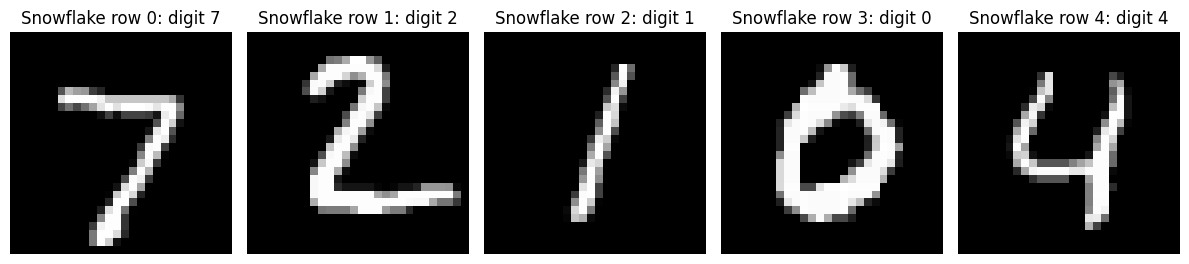

In [ ]:
if USE_SNOWFLAKE:
    with conn.cursor() as cur:
        cur.execute("SELECT sample_id, true_digit, pixels FROM ORCH_COMPARE_DB.PUBLIC.MNIST_SAMPLES WHERE run_id = %s ORDER BY sample_id LIMIT 5", (ml_result["run_id"],))
        sample_rows = cur.fetchall()  # Actual database results.
    fig, axes = plt.subplots(1, len(sample_rows), figsize=(12, 3), squeeze=False)
    for ax, (sample_id, digit, raw_pixels) in zip(axes.ravel(), sample_rows):
        pixels = json.loads(raw_pixels) if isinstance(raw_pixels, str) else raw_pixels  # Parse connector VARIANT text.
        ax.imshow(np.asarray(pixels).reshape(28, 28), cmap="gray", vmin=0, vmax=255)  # Reconstruct stored image.
        ax.set_title(f"Snowflake row {sample_id}: digit {digit}")
        ax.axis("off")
    plt.tight_layout(); plt.show()

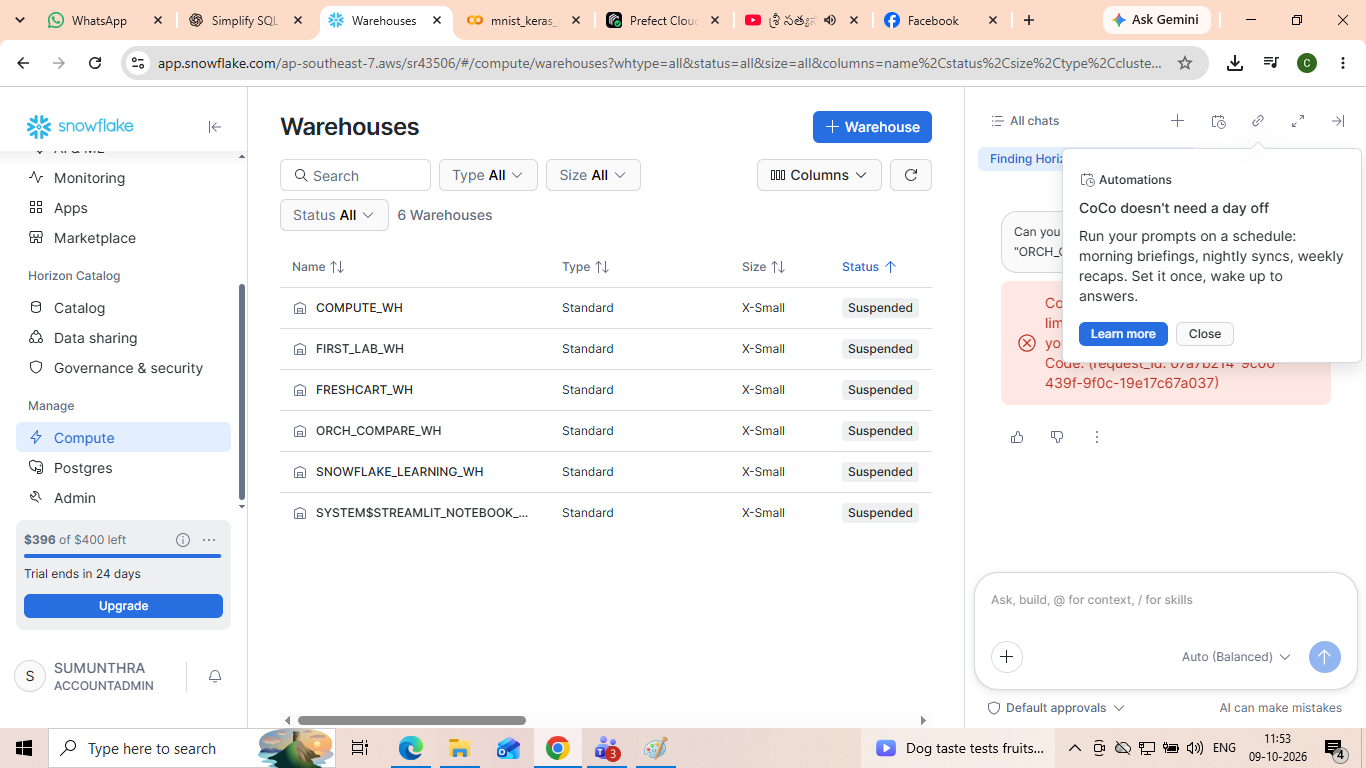

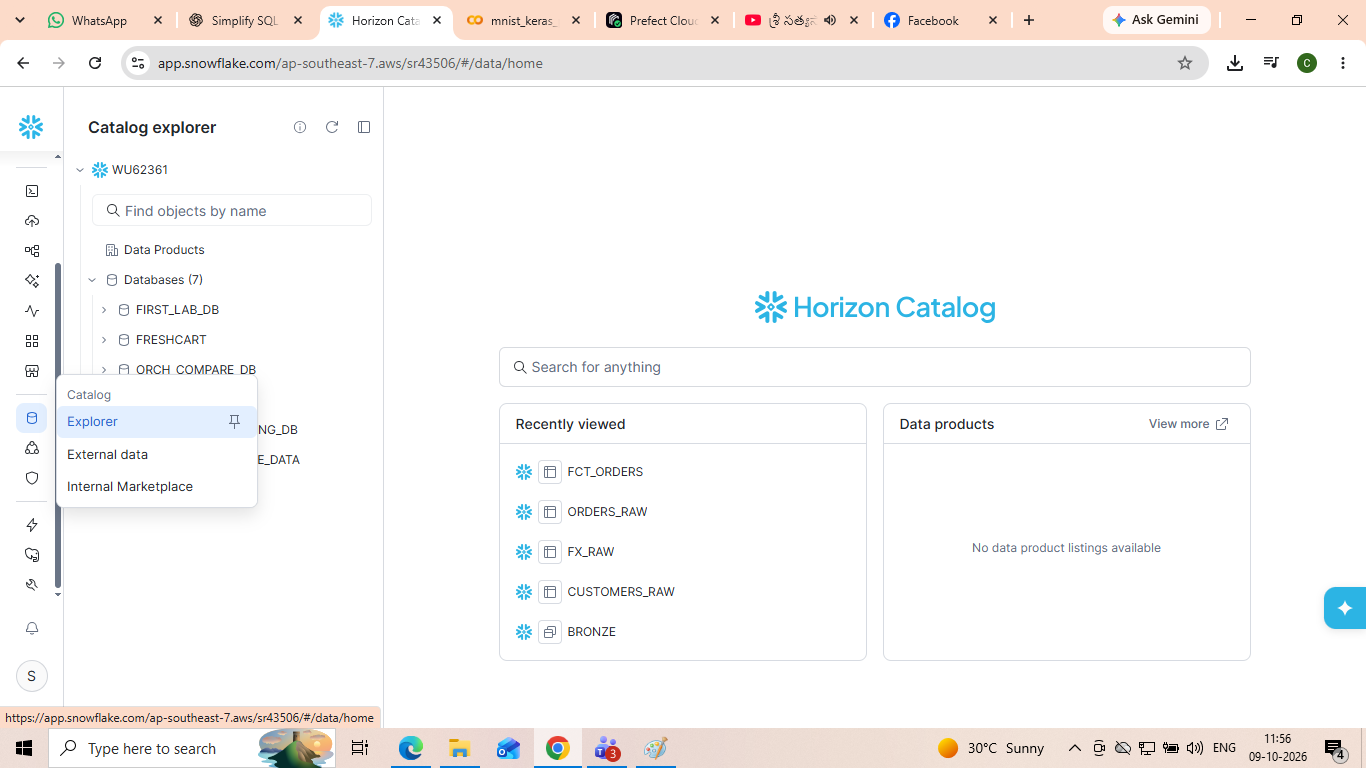

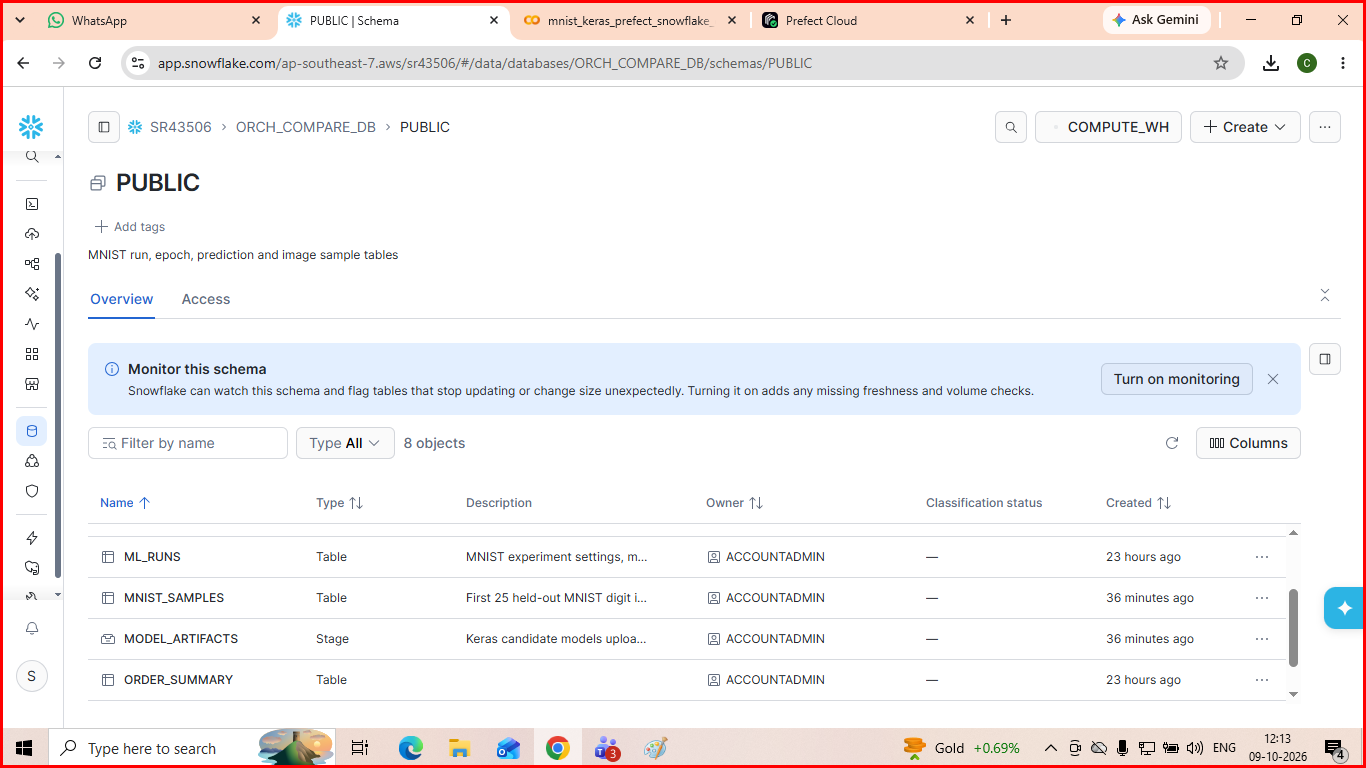

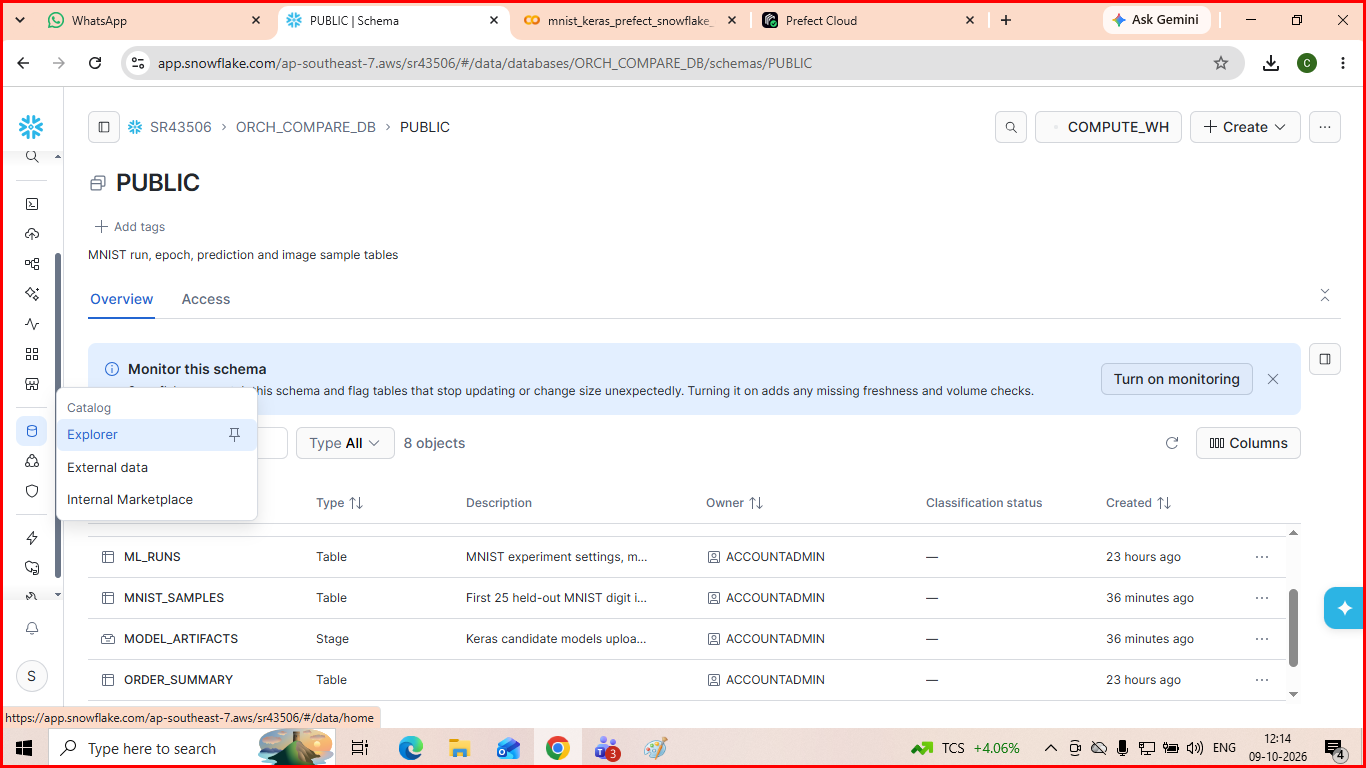

## 13. Run SQL directly in Snowflake: click-by-click
1. Sign in to the same Snowflake account used by this notebook.
2. From the left navigation, open **Projects** and create/open a SQL worksheet (some layouts call this Workspaces).
3. Paste the SQL below. Run one labeled block at a time so each Results grid is easy to inspect.
4. Start with A to select ACCOUNTADMIN, ORCH_COMPARE_WH, ORCH_COMPARE_DB and PUBLIC.
5. Run B/C/E to inspect objects and comments; run F–K to read actual ML rows; run L to list model files.
6. To browse tables visually, open **Catalog** and locate ORCH_COMPARE_DB → PUBLIC → the desired table. If your layout offers Data Preview, open it; SELECT queries provide the same stored rows reliably.

Tables can be empty before recording succeeds. An older ORDERS table may still be visible from prior lessons; the four ML tables listed here belong to MNIST. A blank mistake query means no mistakes were present in the stored sample, not necessarily zero errors on all test images.

```sql
-- A. Select the same account role, compute and storage context as Colab.
USE ROLE ACCOUNTADMIN;
USE WAREHOUSE ORCH_COMPARE_WH;
USE DATABASE ORCH_COMPARE_DB;
USE SCHEMA PUBLIC;

-- B. Locate compute, database, schemas and tables; check the COMMENT columns.
SHOW WAREHOUSES LIKE 'ORCH_COMPARE_WH';
SHOW DATABASES LIKE 'ORCH_COMPARE_DB';
SHOW SCHEMAS IN DATABASE ORCH_COMPARE_DB;
SHOW TABLES IN SCHEMA ORCH_COMPARE_DB.PUBLIC;
SHOW STAGES IN SCHEMA ORCH_COMPARE_DB.PUBLIC;

-- C. See each column's name, type and saved description.
DESCRIBE TABLE ORCH_COMPARE_DB.PUBLIC.ML_RUNS;
DESCRIBE TABLE ORCH_COMPARE_DB.PUBLIC.ML_EPOCHS;
DESCRIBE TABLE ORCH_COMPARE_DB.PUBLIC.ML_PREDICTIONS;
DESCRIBE TABLE ORCH_COMPARE_DB.PUBLIC.MNIST_SAMPLES;

-- D. Read table-level documentation.
SELECT TABLE_CATALOG, TABLE_SCHEMA, TABLE_NAME, COMMENT
FROM ORCH_COMPARE_DB.INFORMATION_SCHEMA.TABLES
WHERE TABLE_SCHEMA = 'PUBLIC'
  AND TABLE_NAME IN ('ML_RUNS','ML_EPOCHS','ML_PREDICTIONS','MNIST_SAMPLES')
ORDER BY TABLE_NAME;

-- E. Read every saved column comment.
SELECT TABLE_NAME, COLUMN_NAME, DATA_TYPE, COMMENT
FROM ORCH_COMPARE_DB.INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_SCHEMA = 'PUBLIC'
  AND TABLE_NAME IN ('ML_RUNS','ML_EPOCHS','ML_PREDICTIONS','MNIST_SAMPLES')
ORDER BY TABLE_NAME, ORDINAL_POSITION;

-- F. Inspect all experiments; metrics are measured by Keras in Colab.
SELECT RUN_ID, TRAIN_SIZE, VAL_SIZE, TEST_SIZE, EPOCHS,
       ROUND(100 * VAL_ACCURACY, 2) AS VAL_ACCURACY_PERCENT,
       ROUND(100 * TEST_ACCURACY, 2) AS TEST_ACCURACY_PERCENT,
       TEST_LOSS, TRAIN_SECONDS, DECISION, MODEL_STAGE_URI, CREATED_AT
FROM ORCH_COMPARE_DB.PUBLIC.ML_RUNS
ORDER BY CREATED_AT DESC;

-- G. Pick the newest completed experiment automatically; no ID placeholder needed.
SET selected_run = (SELECT RUN_ID FROM ORCH_COMPARE_DB.PUBLIC.ML_RUNS
                    ORDER BY CREATED_AT DESC LIMIT 1);
SELECT $selected_run AS SELECTED_EXPERIMENT;

-- H. Read its learning curves, sample predictions and image rows.
SELECT * FROM ORCH_COMPARE_DB.PUBLIC.ML_EPOCHS
WHERE RUN_ID = $selected_run ORDER BY EPOCH;
SELECT * FROM ORCH_COMPARE_DB.PUBLIC.ML_PREDICTIONS
WHERE RUN_ID = $selected_run ORDER BY SAMPLE_ID LIMIT 20;
SELECT SAMPLE_ID, TRUE_DIGIT, SPLIT_NAME, ARRAY_SIZE(PIXELS) AS PIXEL_COUNT,
       PIXELS[0]::INTEGER AS FIRST_PIXEL, PIXELS
FROM ORCH_COMPARE_DB.PUBLIC.MNIST_SAMPLES
WHERE RUN_ID = $selected_run ORDER BY SAMPLE_ID LIMIT 5;

-- I. Count ACTUAL rows for this experiment using COUNT, not metadata estimates.
SELECT 'ML_RUNS' AS TABLE_NAME, COUNT(*) AS ROWS_FOR_RUN FROM ML_RUNS WHERE RUN_ID = $selected_run
UNION ALL
SELECT 'ML_EPOCHS', COUNT(*) FROM ML_EPOCHS WHERE RUN_ID = $selected_run
UNION ALL
SELECT 'ML_PREDICTIONS', COUNT(*) FROM ML_PREDICTIONS WHERE RUN_ID = $selected_run
UNION ALL
SELECT 'MNIST_SAMPLES', COUNT(*) FROM MNIST_SAMPLES WHERE RUN_ID = $selected_run;

-- J. Find wrong predictions in the 100-row stored sample.
SELECT SAMPLE_ID, TRUE_DIGIT, PREDICTED_DIGIT, CONFIDENCE
FROM ML_PREDICTIONS WHERE RUN_ID = $selected_run AND CORRECT = FALSE
ORDER BY SAMPLE_ID;

-- K. Calculate sample accuracy; this is NOT full-test accuracy.
SELECT COUNT(*) AS STORED_PREDICTIONS,
       ROUND(100 * AVG(CASE WHEN CORRECT THEN 1.0 ELSE 0.0 END), 2) AS SAMPLE_ACCURACY_PERCENT
FROM ML_PREDICTIONS WHERE RUN_ID = $selected_run;

-- L. List model files stored in the internal stage.
LIST @ORCH_COMPARE_DB.PUBLIC.MODEL_ARTIFACTS;
```

## 14. Inspect Prefect and repeat the practical
Open the configured workspace → Runs → **mnist-keras-prefect-snowflake**. View the seven task runs and their logs. Check train_classifier for fit time, evaluate_classifier for measured metrics, upload_model for the stage path and record_experiment for the completed RUN_ID.

Change EPOCHS and rerun the flow to create a new experiment. Use validation metrics to compare choices; keep the test split as a final assessment rather than repeatedly optimizing against it. Historical runs stay in Snowflake and models stay in the stage. Random seeds improve repeatability but hardware/software differences can still affect results.

**Troubleshooting:**
- Object not found: run the setup cell, use the same account/role, and check SHOW DATABASES/SHOW TABLES.
- Empty tables: run the entire flow and inspect whether record_experiment completed.
- Access denied: your selected role needs access to the lesson objects and stage.
- Connection or authentication error: reconnect using your institution's MFA/SSO requirements.
- PUT failure: inspect the upload_model task; the local model may still exist even if uploading failed.

The saved candidate is not a production inference endpoint. Confident softmax scores are not calibrated probabilities of correctness. Local JSON manifests should be downloaded before Colab ends; model files uploaded to the internal stage remain in Snowflake.

References:
- https://docs.snowflake.com/en/sql-reference/sql/comment
- https://docs.snowflake.com/en/sql-reference/sql/put
- https://docs.snowflake.com/en/sql-reference/info-schema/columns
- https://www.tensorflow.org/api_docs/python/tf/keras/datasets/mnist/load_data


**Block summary:** Download artifacts before the Colab runtime ends; close the database only after the lesson.

In [ ]:
1. Open a SQL worksheet
In Snowflake, open Projects → Worksheets (or Workspaces, depending on your layout), then create a SQL worksheet. Paste the following blocks and run them one at a time using ▶ Run.
2. Select your warehouse, database, and schema
-- Choose the role used by your notebook.
USE ROLE ACCOUNTADMIN;

-- Choose the compute warehouse.
USE WAREHOUSE ORCH_COMPARE_WH;

-- Choose the database containing our MNIST tables.
USE DATABASE ORCH_COMPARE_DB;

-- Choose the schema containing those tables.
USE SCHEMA PUBLIC;

-- Confirm the selected context.
SELECT CURRENT_WAREHOUSE(), CURRENT_DATABASE(), CURRENT_SCHEMA();

3. Add saved comments to the tables
COMMENT ON TABLE ML_RUNS IS
'One row per MNIST training run: configuration, accuracy, and model location.';

COMMENT ON TABLE ML_EPOCHS IS
'Training and validation loss and accuracy for each epoch.';

COMMENT ON TABLE ML_PREDICTIONS IS
'Predictions for the first 100 test images from each run.';

COMMENT ON TABLE MNIST_SAMPLES IS
'First 25 test images from each run, stored as pixel arrays with true digit labels.';

These commands update the descriptions without changing the table rows.
4. Add saved comments to selected columns
COMMENT ON COLUMN ML_RUNS.RUN_ID IS
'Unique identifier connecting the records from one pipeline run.';

COMMENT ON COLUMN ML_RUNS.TEST_ACCURACY IS
'Accuracy on the full MNIST test set, stored between 0 and 1.';

COMMENT ON COLUMN ML_PREDICTIONS.TRUE_DIGIT IS
'Actual digit label: an integer from 0 to 9.';

COMMENT ON COLUMN ML_PREDICTIONS.PREDICTED_DIGIT IS
'Digit predicted by the trained Keras model.';

COMMENT ON COLUMN ML_PREDICTIONS.CORRECT IS
'TRUE when the predicted digit matches the actual digit.';

COMMENT ON COLUMN MNIST_SAMPLES.PIXELS IS
'784 pixel values representing one 28 by 28 grayscale image.';

5. View only table names and their comments
SELECT TABLE_NAME, COMMENT
FROM ORCH_COMPARE_DB.INFORMATION_SCHEMA.TABLES
WHERE TABLE_SCHEMA = 'PUBLIC'
  AND TABLE_NAME IN (
    'ML_RUNS',
    'ML_EPOCHS',
    'ML_PREDICTIONS',
    'MNIST_SAMPLES'
  )
ORDER BY TABLE_NAME;

6. View only column names and their saved comments
SELECT TABLE_NAME, COLUMN_NAME, COMMENT
FROM ORCH_COMPARE_DB.INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_SCHEMA = 'PUBLIC'
  AND TABLE_NAME IN (
    'ML_RUNS',
    'ML_EPOCHS',
    'ML_PREDICTIONS',
    'MNIST_SAMPLES'
  )
  AND COMMENT IS NOT NULL
ORDER BY TABLE_NAME, ORDINAL_POSITION;

7. Run a query to see the data
-- Show the latest five training runs.
SELECT RUN_ID, TEST_ACCURACY, DECISION, CREATED_AT
FROM ML_RUNS
ORDER BY CREATED_AT DESC
LIMIT 5;

-- Show ten stored predictions.
SELECT SAMPLE_ID, TRUE_DIGIT, PREDICTED_DIGIT, CORRECT
FROM ML_PREDICTIONS
LIMIT 10;

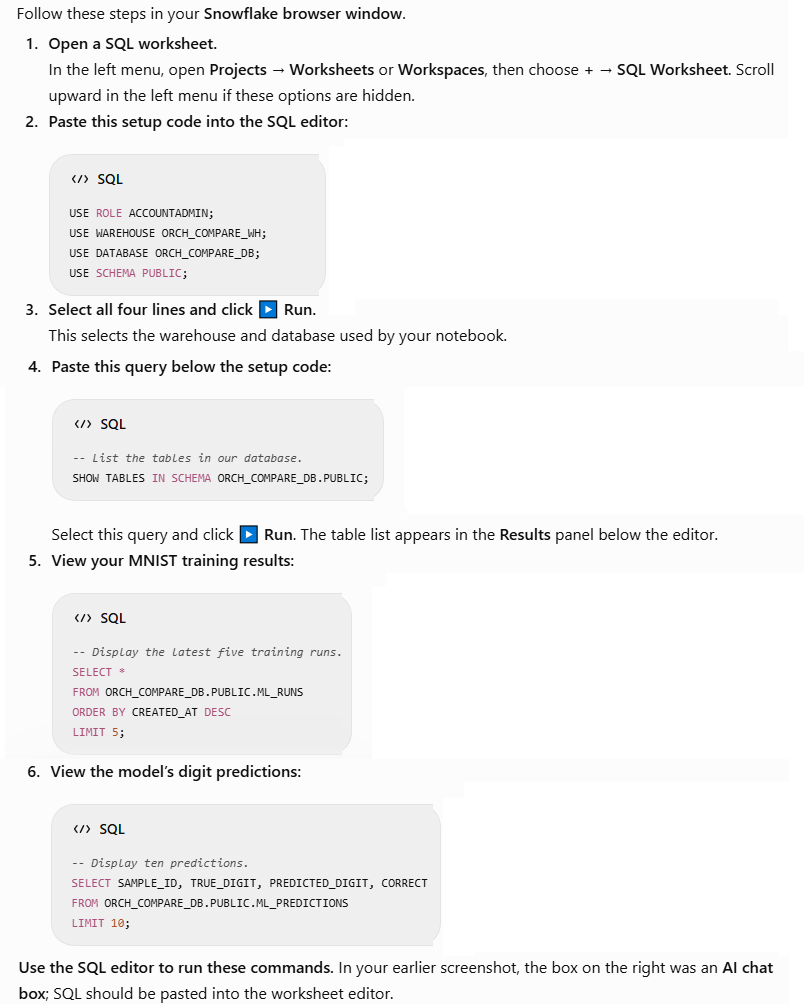